# Common-Source Collapse Verification and Mixed-Tracking Classification

This notebook adds one verification stage to the manuscript's existing carrier-phase double-difference (DD) AoA method. It does **not** replace the DD measurement model, reference-PRN processing, AoA reconstruction, temporal continuity, or ephemeris comparison.

The added stage tests the physical single-transmitter property

$$\mu_i^{\mathrm{spoof}} \approx \mu_j^{\mathrm{spoof}} \approx \mu_s,$$

where $\mu=\cos\alpha$ is the baseline-projected direction cosine and $\mu_s$ is the common transmitter direction. Rather than thresholding each satellite's absolute DD-vs-ephemeris AoA error, the method asks whether a **group** of claimed satellites has collapsed to one measured spatial signature.

The controlled counterfeit labels are isolated from group discovery and are introduced only in the final post-hoc evaluation.

## 1. Relationship to the journal method

The journal first estimates a baseline-relative AoA $\widehat\alpha_{i,k}^{DD}$ and compares it with the ephemeris-based angle $\alpha_{i,k}^{eph}$. A satellite-level error such as

$$e_{i,k}^{\alpha}=\left|\widehat\alpha_{i,k}^{DD}-\alpha_{i,k}^{eph}\right|$$

is useful as a diagnostic but is not reliably separable in mixed tracking: a spoof source can accidentally lie near one claimed satellite's projected direction, while an authentic signal can be assigned the wrong integer branch $m$.

The added verification therefore uses the same carrier-phase observations but tests a relative group property:

$$\text{different claimed directions} + \text{nearly identical measured directions}\;\Longrightarrow\;\text{common-source evidence}. $$

In [1]:
from itertools import combinations
from pathlib import Path
import importlib

from IPython.display import display
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np
import pandas as pd
import seaborn as sns

import aoa_pipeline
importlib.reload(aoa_pipeline)

from aoa_pipeline import (
    DatasetConfig,
    aggregate_wrapped_pairwise_residuals,
    compute_wrapped_pairwise_residuals,
    find_pairwise_cliques,
    run_dataset,
)

pd.set_option("display.max_columns", 80)
pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid", context="notebook")

## 2. Experiment and decision parameters

Let

$$\rho=\frac{D}{\lambda}$$

be the antenna-baseline length in carrier wavelengths. The present rig uses $D\simeq\lambda$, so $\rho=1$.

Two thresholds are kept conceptually separate:

- $\tau_c$: maximum wrapped pairwise separation for a collapse edge;
- $\tau_d$: minimum ephemeris-predicted separation for that edge to be informative.

The numerical values below are explicit experiment settings, not fitted from the known counterfeit labels. For a confirmatory paper experiment, estimate or predeclare them using independent recordings and freeze them before evaluating mixed tracking.

In [2]:
OUTPUT_DIR = Path("outputs/aoa_paper/common_source_collapse_classifier")
SAVE_OUTPUTS = False

MIXED_START_INDEX = 0
MIXED_ANALYSIS_LENGTH = 34
MIN_TARGET_EPOCHS = 20
MIN_PAIR_EPOCHS = 10
BASELINE_OVER_WAVELENGTH = 1.0

COLLAPSE_THRESHOLD_CYCLES = 0.03
EXPECTED_SEPARATION_THRESHOLD_CYCLES = 0.05
MIN_GROUP_SIZE = 3
MIN_INFORMATIVE_EDGES = 2
MIN_INFORMATIVE_EDGE_FRACTION = 0.50

MIXED_CONFIG = DatasetConfig(
    name="common_source_collapse_classifier/mixed_tracking",
    receiver1_path=Path("dataset/sp-partial-19-06/18-06/COM3___9600_260618_095042.ubx"),
    receiver2_path=Path("dataset/sp-partial-19-06/18-06/COM4___9600_260618_095054.ubx"),
    start_index=MIXED_START_INDEX,
    length=MIXED_ANALYSIS_LENGTH,
    alpha_r_deg=None,
    reference_svid=None,
    selected_svids=None,
    excluded_reference_svids=None,
    reference_required_svids=None,
    excluded_analysis_svids=None,
    sync_tow_decimals=0,
    use_navpvt_time_correction=True,
    single_difference_order="rx2-rx1",
    navsat_azimuth_bias_deg=0.0,
    baseline_over_wavelength=BASELINE_OVER_WAVELENGTH,
)

def show_figure(fig, filename):
    if SAVE_OUTPUTS:
        OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(OUTPUT_DIR / filename, dpi=220, bbox_inches="tight")
    display(fig)
    plt.close(fig)

display(pd.DataFrame([{
    "dataset": "Mixed tracking",
    "epochs": MIXED_CONFIG.length,
    "baseline_over_wavelength": BASELINE_OVER_WAVELENGTH,
    "collapse_threshold_cycles": COLLAPSE_THRESHOLD_CYCLES,
    "expected_separation_threshold_cycles": EXPECTED_SEPARATION_THRESHOLD_CYCLES,
    "minimum_group_size": MIN_GROUP_SIZE,
    "uses_known_labels_for_discovery": False,
}]))

,dataset,epochs,baseline_over_wavelength,collapse_threshold_cycles,expected_separation_threshold_cycles,minimum_group_size,uses_known_labels_for_discovery
0,Mixed tracking,34,1.0,0.03,0.05,3,False


## 3. Existing carrier-phase measurement path

For PRN $i$, define the synchronized inter-receiver single difference in carrier cycles as

$$s_{i,k}=\phi_{2,i,k}-\phi_{1,i,k}.$$

Using journal reference PRN $r$, the ordinary inter-satellite DD is

$$DD_{ir,k}=s_{i,k}-s_{r,k}.$$

The notebook runs the existing data pipeline to obtain $s_{i,k}$ and epoch-matched ephemeris geometry. The added classifier does not consume the pipeline's DP-selected AoA tracks, so integer branch $m$ cannot be selected differently for known authentic and spoof satellites.

In [3]:
mixed_run = run_dataset(MIXED_CONFIG)

available_svids = sorted(
    set(map(int, mixed_run.single_difference_cycles.columns))
    | set(map(int, mixed_run.ephemeris_aoa_deg.columns))
)
availability = pd.DataFrame({
    "svid": available_svids,
    "single_difference_epochs": [
        int(mixed_run.single_difference_cycles.get(svid, pd.Series(dtype=float)).notna().sum())
        for svid in available_svids
    ],
    "ephemeris_epochs": [
        int(mixed_run.ephemeris_aoa_deg.get(svid, pd.Series(dtype=float)).notna().sum())
        for svid in available_svids
    ],
})
availability["eligible"] = availability[["single_difference_epochs", "ephemeris_epochs"]].min(axis=1).ge(MIN_TARGET_EPOCHS)

print(f"Synchronized epochs: {len(mixed_run.epochs)}")
print(f"Pipeline DD reference PRN: {mixed_run.reference_svid} (the added statistic cancels it)")
display(availability)

Synchronized epochs: 34
Pipeline DD reference PRN: 20 (the added statistic cancels it)


,svid,single_difference_epochs,ephemeris_epochs,eligible
0,6,34,30,True
1,9,34,30,True
2,10,34,34,True
3,11,34,30,True
4,12,34,34,True
5,13,34,0,False
6,15,34,34,True
7,18,34,34,True
8,20,34,30,True
9,23,34,34,True


## 4. The additional statistic cancels the DD reference

For any target pair $(i,j)$, subtract the two ordinary DD measurements that used the same reference $r$:

$$\begin{aligned}
y_{ij,k}^{(r)}
&=DD_{ir,k}-DD_{jr,k}\\
&=(s_{i,k}-s_{r,k})-(s_{j,k}-s_{r,k})\\
&=s_{i,k}-s_{j,k}=y_{ij,k}.
\end{aligned}$$

Thus $y_{ij,k}$ is already available from the journal's measurements, and its value does not depend on whether the chosen reference is authentic or spoofed. The numerical check below verifies this identity for one observed pair.

In [4]:
eligible_for_check = availability.loc[availability.eligible, "svid"].astype(int).tolist()
reference_svid = int(mixed_run.reference_svid)
check_targets = [svid for svid in eligible_for_check if svid != reference_svid][:2]
if len(check_targets) >= 2:
    left_svid, right_svid = check_targets
    sd = mixed_run.single_difference_cycles
    dd_left = sd[left_svid] - sd[reference_svid]
    dd_right = sd[right_svid] - sd[reference_svid]
    reference_form = (dd_left - dd_right).rename("reference_form")
    direct_form = (sd[left_svid] - sd[right_svid]).rename("direct_form")
    check = pd.concat([reference_form, direct_form], axis=1).dropna()
    check["absolute_numerical_difference"] = (check.reference_form - check.direct_form).abs()
    display(pd.DataFrame([{
        "checked_pair": f"PRN {left_svid}–PRN {right_svid}",
        "reference_svid": reference_svid,
        "shared_epochs": len(check),
        "maximum_absolute_numerical_difference": check.absolute_numerical_difference.max(),
    }]))
    assert np.allclose(check.reference_form, check.direct_form)

,checked_pair,reference_svid,shared_epochs,maximum_absolute_numerical_difference
0,PRN 6–PRN 9,20,34,0.0


## 5. Common-source collapse residual

For signals $i$ and $j$ transmitted by one physical antenna, their receiver single differences share the same source projection $\mu_{s,k}$ and common receiver term $\beta_k$:

$$s_{i,k}=\rho\mu_{s,k}+N_i+\beta_k+\epsilon_{i,k},$$

$$s_{j,k}=\rho\mu_{s,k}+N_j+\beta_k+\epsilon_{j,k}.$$

Their pairwise DD is consequently

$$y_{ij,k}=N_i-N_j+\epsilon_{ij,k}.$$

Define wrapping in cycles as

$$\operatorname{wrap}(x)=\left((x+\tfrac12)\bmod1\right)-\tfrac12,$$

and the epoch-level common-source collapse residual as

$$c_{ij,k}=\left|\operatorname{wrap}(y_{ij,k})\right|.$$

Wrapping removes the integer $N_i-N_j$. Therefore, two signals from the same antenna satisfy $c_{ij,k}\approx0$ without reconstructing $\alpha_i$, choosing $m$, or trusting a reference angle.

## 6. Expected geometry and collapse contradiction

A small measured separation can also occur when two authentic satellites have similar projected directions. The expected ephemeris pair separation is therefore

$$e_{ij,k}=\rho\left(\mu_{i,k}^{eph}-\mu_{j,k}^{eph}\right),\qquad \mu_{i,k}^{eph}=\cos\alpha_{i,k}^{eph},$$

with wrapped magnitude

$$d_{ij,k}=\left|\operatorname{wrap}(e_{ij,k})\right|.$$

The existing ephemeris-consistency idea is retained through

$$q_{ij,k}=\left|\operatorname{wrap}(y_{ij,k}-e_{ij,k})\right|.$$

Finally, define the common-source incompatibility or collapse-contradiction evidence

$$I_{ij,k}=d_{ij,k}-c_{ij,k}.$$

For an authentic pair, measured and predicted pair separations should be similar, so $I_{ij}$ is near zero. For an informative same-source pair, $c_{ij}$ is near zero while $d_{ij}$ is appreciable, making $I_{ij}$ positive. If both $c_{ij}$ and $d_{ij}$ are near zero, the pair is geometrically aliased and should not be treated as independent spoof evidence.

## 7. Robust temporal aggregation and pair decisions

The epoch values are summarized with medians over the common valid window:

$$\bar c_{ij}=\operatorname{median}_{k}\,c_{ij,k},\qquad\bar d_{ij}=\operatorname{median}_{k}\,d_{ij,k},$$

$$\bar q_{ij}=\operatorname{median}_{k}\,q_{ij,k},\qquad\bar I_{ij}=\operatorname{median}_{k}\,I_{ij,k}.$$

A collapse edge is declared when

$$B_{ij}=\mathbf 1\!\left[\bar c_{ij}\le\tau_c\right].$$

That edge provides strong common-source evidence only when the claimed geometry was sufficiently separated:

$$H_{ij}=\mathbf 1\!\left[\bar c_{ij}\le\tau_c\right]\,\mathbf 1\!\left[\bar d_{ij}\ge\tau_d\right].$$

In [5]:
epoch_pair_statistics = compute_wrapped_pairwise_residuals(
    mixed_run.single_difference_cycles,
    mixed_run.ephemeris_aoa_deg,
    min_target_epochs=MIN_TARGET_EPOCHS,
    baseline_over_wavelength=BASELINE_OVER_WAVELENGTH,
)
pair_statistics = aggregate_wrapped_pairwise_residuals(
    epoch_pair_statistics,
    min_epochs_per_pair=MIN_PAIR_EPOCHS,
).copy()

pair_statistics["collapse_edge"] = pair_statistics.median_common_source_collapse.le(COLLAPSE_THRESHOLD_CYCLES)
pair_statistics["informative_geometry"] = pair_statistics.median_expected_separation.ge(EXPECTED_SEPARATION_THRESHOLD_CYCLES)
pair_statistics["common_source_evidence_edge"] = pair_statistics.collapse_edge & pair_statistics.informative_geometry
pair_statistics["pair_interpretation"] = np.select(
    [
        pair_statistics.common_source_evidence_edge,
        pair_statistics.collapse_edge & ~pair_statistics.informative_geometry,
    ],
    ["collapsed and ephemeris-distinct", "collapsed but geometrically aliased"],
    default="not collapsed",
)

eligible_svids = sorted(
    set(pair_statistics.left_svid.astype(int))
    | set(pair_statistics.right_svid.astype(int))
)
display(pd.DataFrame([{
    "eligible_satellite_count": len(eligible_svids),
    "eligible_svids": tuple(eligible_svids),
    "epoch_pair_observations": len(epoch_pair_statistics),
    "aggregated_pair_count": len(pair_statistics),
    "collapse_edges": int(pair_statistics.collapse_edge.sum()),
    "informative_common_source_edges": int(pair_statistics.common_source_evidence_edge.sum()),
}]))
display(pair_statistics[[
    "pair", "median_common_source_collapse", "median_expected_separation",
    "median_common_source_incompatibility", "median_wrapped_geometry_residual",
    "epoch_count", "pair_interpretation",
]].sort_values(["median_common_source_collapse", "median_expected_separation"]).round(5))

,eligible_satellite_count,eligible_svids,epoch_pair_observations,aggregated_pair_count,collapse_edges,informative_common_source_edges
0,11,"(6, 9, 10, 11, 12, 15, 18, 20, 23, 24, 32)",1724,55,6,5


,pair,median_common_source_collapse,median_expected_separation,median_common_source_incompatibility,median_wrapped_geometry_residual,epoch_count,pair_interpretation
30,PRN 11–PRN 20,0.00302,0.33508,0.33206,0.33481,30,collapsed and ephemeris-distinct
15,PRN 9–PRN 20,0.00390,0.09206,0.08815,0.09153,30,collapsed and ephemeris-distinct
11,PRN 9–PRN 11,0.00439,0.42713,0.42274,0.42847,30,collapsed and ephemeris-distinct
2,PRN 6–PRN 11,0.01033,0.33192,0.32159,0.33315,30,collapsed and ephemeris-distinct
0,PRN 6–PRN 9,0.01072,0.09522,0.08449,0.09519,30,collapsed and ephemeris-distinct
6,PRN 6–PRN 20,0.01082,0.00316,-0.00766,0.00922,30,collapsed but geometrically aliased
44,PRN 15–PRN 32,0.03672,0.17971,0.14299,0.16144,33,not collapsed
37,PRN 12–PRN 23,0.03841,0.25055,0.21215,0.21215,34,not collapsed
46,PRN 18–PRN 23,0.04061,0.07138,0.02898,0.03049,34,not collapsed
40,PRN 15–PRN 18,0.05531,0.05619,0.00088,0.11150,34,not collapsed


## 8. Common-source group extraction

The collapse matrix $B=[B_{ij}]$ is treated as an undirected graph. A candidate set $S$ must contain at least three PRNs and have collapsed internal pairs. Its collapse tightness and ephemeris diversity are

$$J(S)=\operatorname{median}_{i<j;\,i,j\in S}\bar c_{ij},$$

$$V(S)=\operatorname{median}_{i<j;\,i,j\in S}\bar d_{ij}.$$

The number of informative internal edges is

$$K(S)=\sum_{i<j;\,i,j\in S}H_{ij}.$$

A group is accepted only if it is tightly collapsed **and** contains enough pairs whose claimed ephemeris directions were distinct. This prevents the decision from being based only on the largest cluster and tolerates an individual aliased pair inside a genuine spoof group. Known spoof labels do not enter this search.

In [6]:
collapse_cliques = find_pairwise_cliques(
    pair_statistics,
    edge_value_column="median_common_source_collapse",
    edge_threshold=COLLAPSE_THRESHOLD_CYCLES,
    min_clique_size=MIN_GROUP_SIZE,
)

candidate_rows = []
for row in collapse_cliques.itertuples():
    group = tuple(map(int, row.clique_svids))
    internal = pair_statistics.loc[
        pair_statistics.left_svid.isin(group)
        & pair_statistics.right_svid.isin(group)
    ]
    informative_edge_count = int(internal.common_source_evidence_edge.sum())
    informative_edge_fraction = informative_edge_count / len(internal) if len(internal) else 0.0
    candidate_rows.append({
        "candidate_group": group,
        "group_size": len(group),
        "internal_pair_count": len(internal),
        "median_internal_collapse": internal.median_common_source_collapse.median(),
        "maximum_internal_collapse": internal.median_common_source_collapse.max(),
        "median_expected_separation": internal.median_expected_separation.median(),
        "median_collapse_incompatibility": internal.median_common_source_incompatibility.median(),
        "informative_edge_count": informative_edge_count,
        "informative_edge_fraction": informative_edge_fraction,
        "validated_common_source_group": (
            informative_edge_count >= MIN_INFORMATIVE_EDGES
            and informative_edge_fraction >= MIN_INFORMATIVE_EDGE_FRACTION
        ),
    })

candidate_groups = pd.DataFrame(candidate_rows)
if not candidate_groups.empty:
    candidate_groups = candidate_groups.sort_values(
        ["validated_common_source_group", "informative_edge_count",
         "median_collapse_incompatibility", "median_internal_collapse"],
        ascending=[False, False, False, True],
    ).reset_index(drop=True)
display(candidate_groups.round(5))

validated = candidate_groups.loc[candidate_groups.validated_common_source_group] if not candidate_groups.empty else candidate_groups
selected_common_source_group = (
    tuple(map(int, validated.iloc[0].candidate_group))
    if not validated.empty
    else ()
)
print(f"Selected common-source group: {selected_common_source_group or 'none'}")

,candidate_group,group_size,internal_pair_count,median_internal_collapse,maximum_internal_collapse,median_expected_separation,median_collapse_incompatibility,informative_edge_count,informative_edge_fraction,validated_common_source_group
0,"(6, 9, 11, 20)",4,6,0.00736,0.01082,0.21357,0.20487,5,0.83333,True


Selected common-source group: (6, 9, 11, 20)


## 9. Pairwise matrices and heatmaps

Four symmetric matrices expose the complete decision evidence:

$$C_{ij}=\bar c_{ij}\quad\text{(measured common-source collapse)},$$

$$D_{ij}=\bar d_{ij}\quad\text{(expected ephemeris separation)},$$

$$I_{ij}=\bar I_{ij}\quad\text{(collapse contradiction)},$$

and the categorical edge matrix

$$M_{ij}=\begin{cases}
2,& C_{ij}\le\tau_c\ \text{and}\ D_{ij}\ge\tau_d,\\
1,& C_{ij}\le\tau_c\ \text{and}\ D_{ij}<\tau_d,\\
0,& C_{ij}>\tau_c.
\end{cases}$$

PRNs in the selected common-source group are ordered first, so their low-collapse block is visible in the upper-left corner.

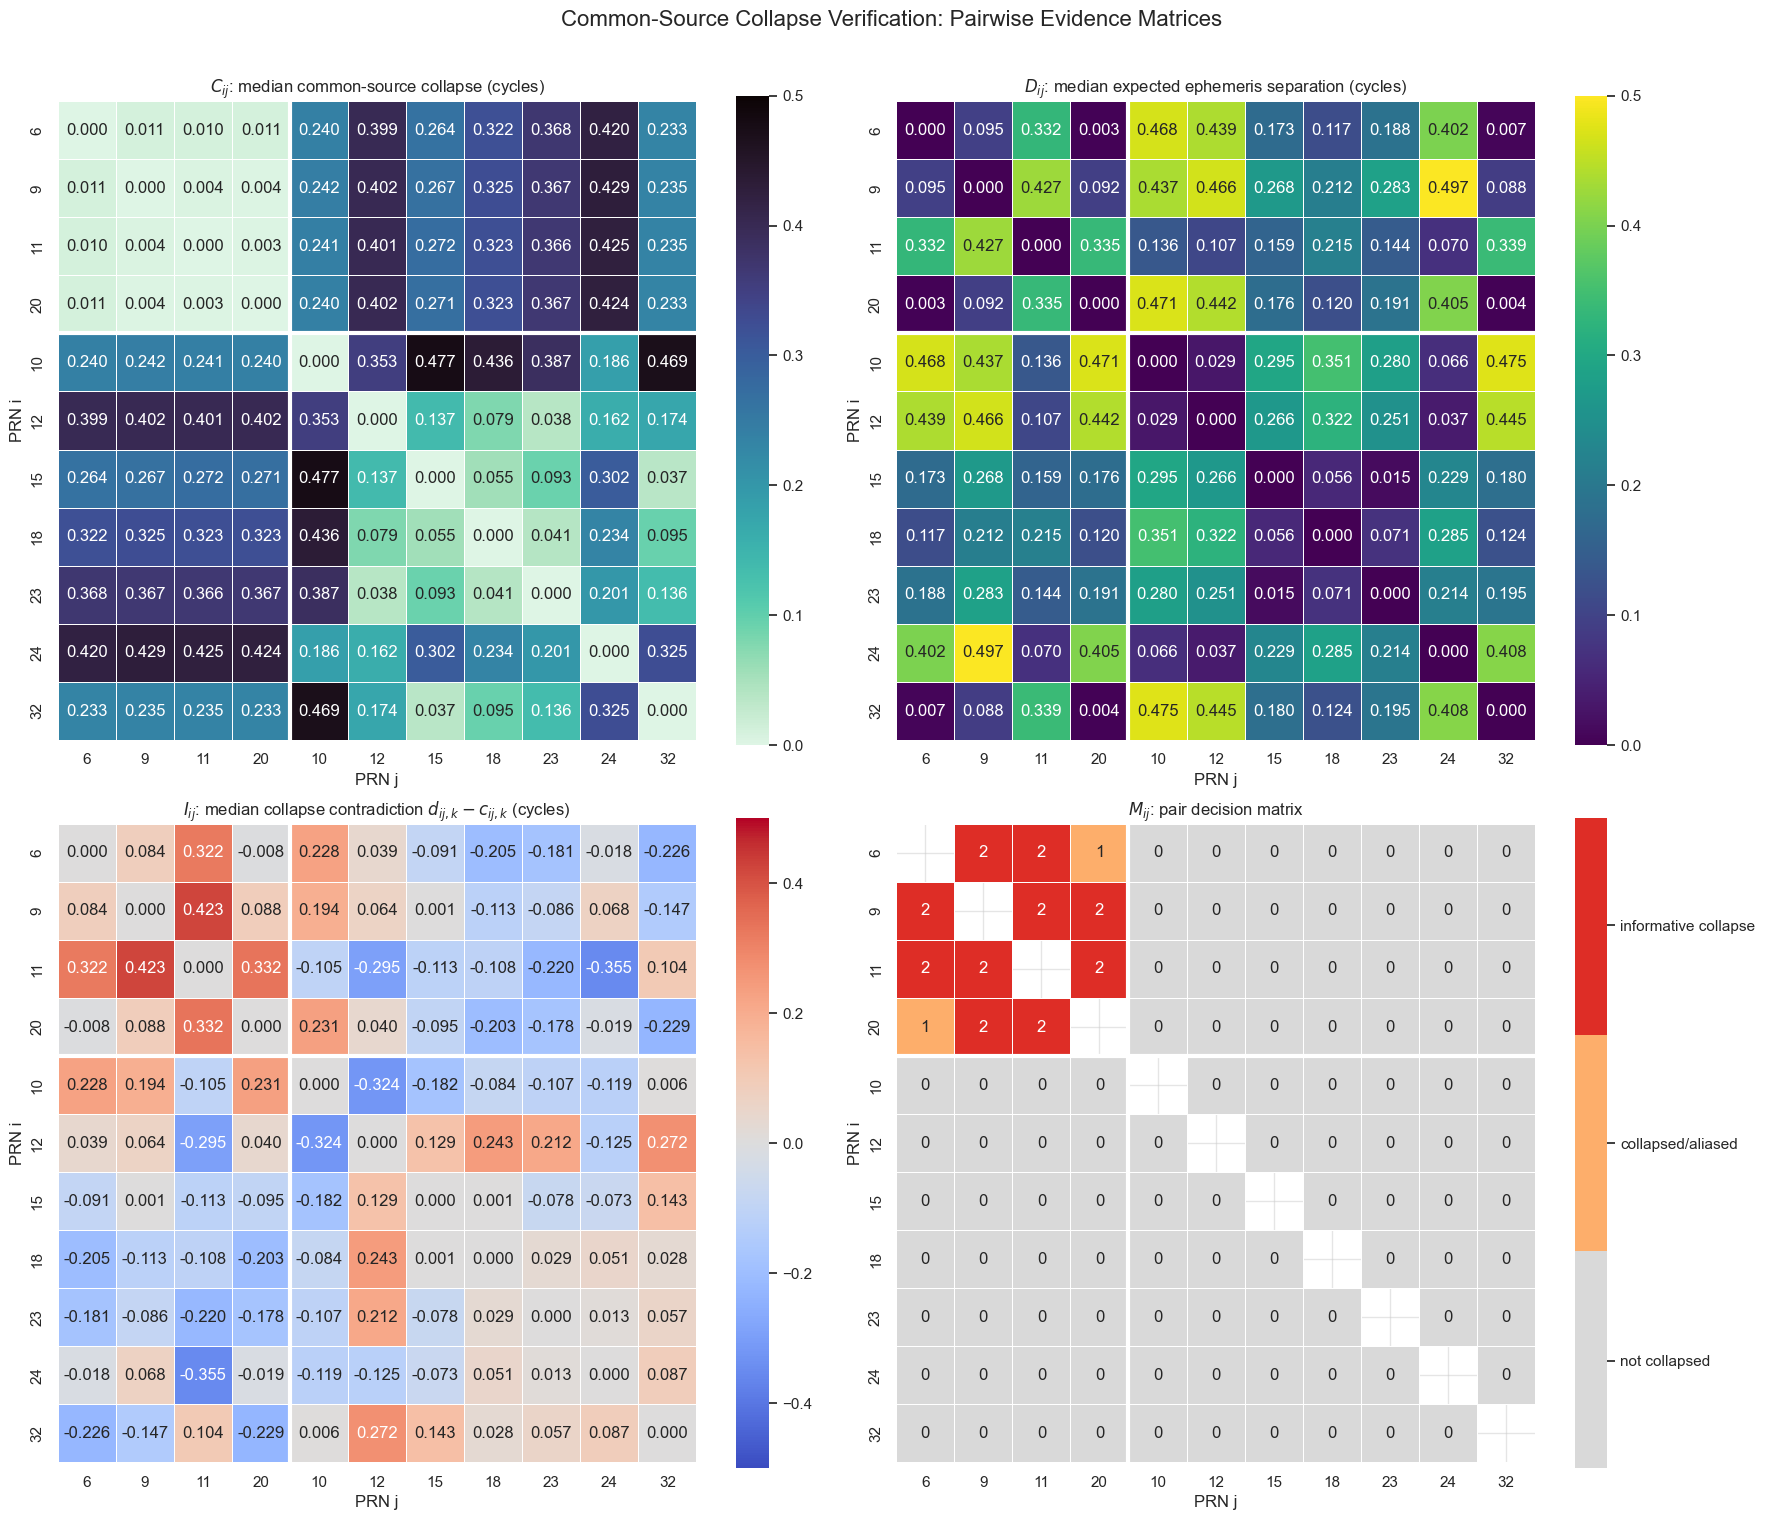

In [7]:
def symmetric_pair_matrix(frame, value_column, diagonal=np.nan):
    matrix = pd.DataFrame(np.nan, index=eligible_svids, columns=eligible_svids, dtype=float)
    for row in frame.itertuples():
        left_svid, right_svid = int(row.left_svid), int(row.right_svid)
        value = float(getattr(row, value_column))
        matrix.loc[left_svid, right_svid] = value
        matrix.loc[right_svid, left_svid] = value
    for svid in eligible_svids:
        matrix.loc[svid, svid] = diagonal
    matrix.index.name = "PRN i"
    matrix.columns.name = "PRN j"
    return matrix

collapse_matrix = symmetric_pair_matrix(pair_statistics, "median_common_source_collapse", diagonal=0.0)
expected_matrix = symmetric_pair_matrix(pair_statistics, "median_expected_separation", diagonal=0.0)
incompatibility_matrix = symmetric_pair_matrix(pair_statistics, "median_common_source_incompatibility", diagonal=0.0)
edge_code = pair_statistics.assign(
    edge_code=np.select(
        [pair_statistics.common_source_evidence_edge, pair_statistics.collapse_edge],
        [2.0, 1.0],
        default=0.0,
    )
)
edge_matrix = symmetric_pair_matrix(edge_code, "edge_code", diagonal=np.nan)

ordered_svids = list(selected_common_source_group) + [
    svid for svid in eligible_svids if svid not in selected_common_source_group
]
collapse_ordered = collapse_matrix.loc[ordered_svids, ordered_svids]
expected_ordered = expected_matrix.loc[ordered_svids, ordered_svids]
incompatibility_ordered = incompatibility_matrix.loc[ordered_svids, ordered_svids]
edge_ordered = edge_matrix.loc[ordered_svids, ordered_svids]

fig, axes = plt.subplots(2, 2, figsize=(18, 15))
sns.heatmap(collapse_ordered, annot=True, fmt=".3f", cmap="mako_r", vmin=0, vmax=0.5, square=True, linewidths=0.4, ax=axes[0, 0])
axes[0, 0].set_title(r"$C_{ij}$: median common-source collapse (cycles)")
sns.heatmap(expected_ordered, annot=True, fmt=".3f", cmap="viridis", vmin=0, vmax=0.5, square=True, linewidths=0.4, ax=axes[0, 1])
axes[0, 1].set_title(r"$D_{ij}$: median expected ephemeris separation (cycles)")
sns.heatmap(incompatibility_ordered, annot=True, fmt=".3f", cmap="coolwarm", center=0, vmin=-0.5, vmax=0.5, square=True, linewidths=0.4, ax=axes[1, 0])
axes[1, 0].set_title(r"$I_{ij}$: median collapse contradiction $d_{ij,k}-c_{ij,k}$ (cycles)")
edge_cmap = ListedColormap(["#d9d9d9", "#fdae6b", "#de2d26"])
edge_ax = sns.heatmap(edge_ordered, annot=True, fmt=".0f", cmap=edge_cmap, vmin=0, vmax=2, square=True, linewidths=0.4, cbar_kws={"ticks": [0.33, 1.0, 1.67]}, ax=axes[1, 1])
edge_ax.collections[0].colorbar.set_ticklabels(["not collapsed", "collapsed/aliased", "informative collapse"])
axes[1, 1].set_title(r"$M_{ij}$: pair decision matrix")

if selected_common_source_group:
    boundary = len(selected_common_source_group)
    for ax in axes.ravel():
        ax.axhline(boundary, color="white", lw=3)
        ax.axvline(boundary, color="white", lw=3)
fig.suptitle("Common-Source Collapse Verification: Pairwise Evidence Matrices", fontsize=16, y=1.01)
fig.tight_layout()
show_figure(fig, "common_source_pairwise_matrices.png")

## 10. General scenario and satellite decision

Let $\mathcal V$ be the eligible tracked PRNs and $\widehat S$ the validated common-source group. The added stage gives the general scenario rule

$$\widehat{\mathcal H}=\begin{cases}
\mathcal H_A,&\widehat S=\varnothing,\\
\mathcal H_F,&\widehat S=\mathcal V,\\
\mathcal H_M,&3\le|\widehat S|<|\mathcal V|,
\end{cases}$$

where $\mathcal H_A$, $\mathcal H_F$, and $\mathcal H_M$ denote no detected common-source spoofing, full spoofing, and mixed tracking.

Under the manuscript's controlled single-spoofer binary model, the per-satellite decision is

$$\widehat z_i=\begin{cases}
\text{counterfeit},&i\in\widehat S,\\
\text{authentic},&i\in\mathcal V\setminus\widehat S.
\end{cases}$$

Outside that stated model, the complement is more conservatively described as `other tracked source` until it independently passes the journal's ephemeris-consistency checks.

In [8]:
if not selected_common_source_group:
    scenario_decision = "No common-source spoofing group detected"
elif set(selected_common_source_group) == set(eligible_svids):
    scenario_decision = "Full spoofing / all eligible PRNs share one source"
else:
    scenario_decision = "Mixed tracking / a strict PRN subset shares one source"

classification = pd.DataFrame({"svid": eligible_svids})
classification["common_source_group_member"] = classification.svid.isin(selected_common_source_group)
classification["predicted_class_under_single_spoofer_model"] = np.where(
    classification.common_source_group_member,
    "Counterfeit",
    "Authentic",
)
classification["conservative_reported_group"] = np.where(
    classification.common_source_group_member,
    "Common-source counterfeit group",
    "Other tracked source",
)

display(pd.DataFrame([{
    "scenario_decision": scenario_decision,
    "selected_common_source_group": selected_common_source_group,
    "selected_group_size": len(selected_common_source_group),
    "eligible_satellite_count": len(eligible_svids),
}]))
display(classification)

,scenario_decision,selected_common_source_group,selected_group_size,eligible_satellite_count
0,Mixed tracking / a strict PRN subset shares on...,"(6, 9, 11, 20)",4,11


,svid,common_source_group_member,predicted_class_under_single_spoofer_model,conservative_reported_group
0,6,True,Counterfeit,Common-source counterfeit group
1,9,True,Counterfeit,Common-source counterfeit group
2,10,False,Authentic,Other tracked source
3,11,True,Counterfeit,Common-source counterfeit group
4,12,False,Authentic,Other tracked source
5,15,False,Authentic,Other tracked source
6,18,False,Authentic,Other tracked source
7,20,True,Counterfeit,Common-source counterfeit group
8,23,False,Authentic,Other tracked source
9,24,False,Authentic,Other tracked source


## 11. Time-domain visualization of the selected collapse

For the selected group, the left panel plots every internal pair's epoch residual

$$c_{ij,k}=\left|\operatorname{wrap}(s_{i,k}-s_{j,k})\right|.$$

The right panel compares the aggregated internal and external pair distributions

$$\left\{\bar c_{ij}:i,j\in\widehat S\right\}\quad\text{versus}\quad\left\{\bar c_{ij}:\{i,j\}\nsubseteq\widehat S\right\}.$$

This is the direct measurement-domain visualization of AoA collapse. Reconstructed AoA tracks may still be shown in the paper for interpretation, but they are not used to discover the group.

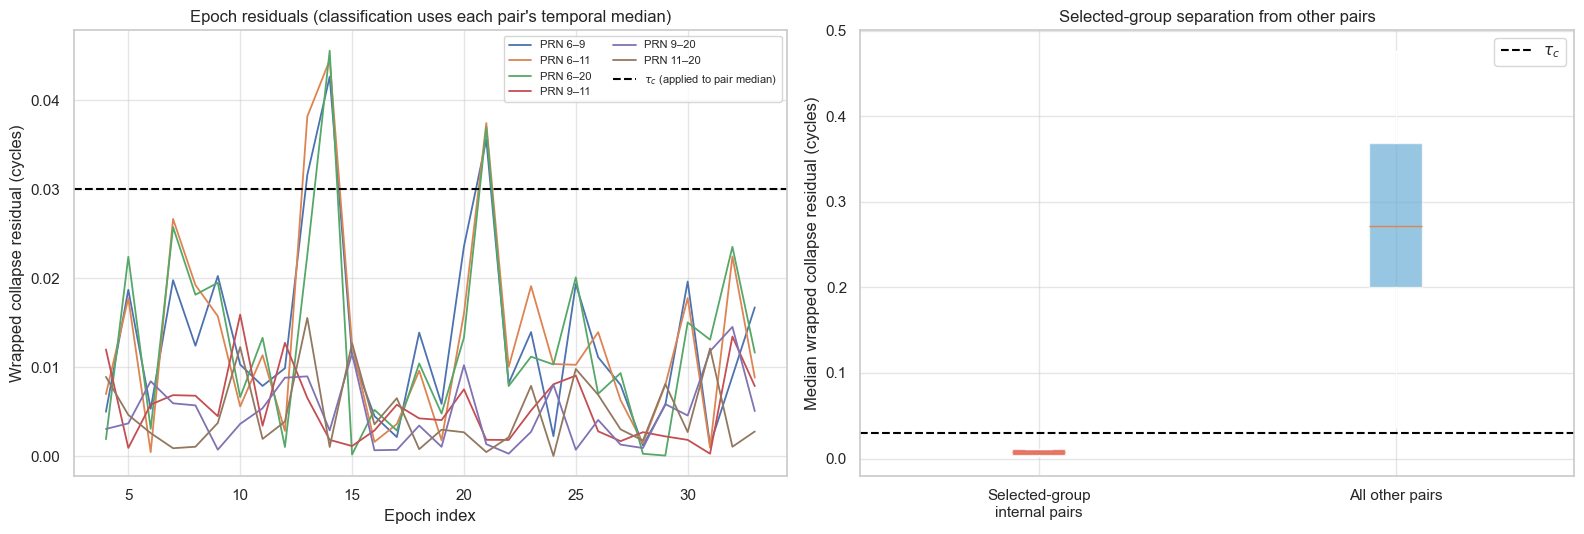

In [9]:
if selected_common_source_group:
    internal_epoch_pairs = epoch_pair_statistics.loc[
        epoch_pair_statistics.left_svid.isin(selected_common_source_group)
        & epoch_pair_statistics.right_svid.isin(selected_common_source_group)
    ].copy()
    internal_aggregated = pair_statistics.loc[
        pair_statistics.left_svid.isin(selected_common_source_group)
        & pair_statistics.right_svid.isin(selected_common_source_group)
    ].copy()
    external_aggregated = pair_statistics.drop(index=internal_aggregated.index).copy()

    fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
    for (left_svid, right_svid), group in internal_epoch_pairs.groupby(["left_svid", "right_svid"]):
        axes[0].plot(
            group.epoch_index,
            group.common_source_collapse_cycles,
            lw=1.3,
            label=f"PRN {int(left_svid)}–{int(right_svid)}",
        )
    axes[0].axhline(COLLAPSE_THRESHOLD_CYCLES, color="black", ls="--", label=r"$\tau_c$ (applied to pair median)")
    axes[0].set_xlabel("Epoch index")
    axes[0].set_ylabel("Wrapped collapse residual (cycles)")
    axes[0].set_title("Epoch residuals (classification uses each pair's temporal median)")
    axes[0].legend(fontsize=8, ncol=2)

    box = axes[1].boxplot(
        [internal_aggregated.median_common_source_collapse, external_aggregated.median_common_source_collapse],
        tick_labels=["Selected-group\ninternal pairs", "All other pairs"],
        showfliers=True,
        patch_artist=True,
    )
    box["boxes"][0].set_facecolor("#de2d26")
    box["boxes"][1].set_facecolor("#6baed6")
    for patch in box["boxes"]:
        patch.set_alpha(0.7)
    axes[1].axhline(COLLAPSE_THRESHOLD_CYCLES, color="black", ls="--", label=r"$\tau_c$")
    axes[1].set_ylabel("Median wrapped collapse residual (cycles)")
    axes[1].set_title("Selected-group separation from other pairs")
    axes[1].legend()
    fig.tight_layout()
    show_figure(fig, "selected_common_source_collapse.png")

## 12. Post-hoc controlled-experiment evaluation

Only now are the experiment labels introduced. Let $S^{true}$ be the controlled counterfeit set. Exact recovery is

$$\operatorname{ExactRecovery}=\mathbf 1\!\left[\widehat S=S^{true}\right].$$

Satellite-level accuracy is

$$\operatorname{Accuracy}=\frac{1}{|\mathcal V|}\sum_{i\in\mathcal V}\mathbf 1\!\left[\widehat z_i=z_i^{true}\right].$$

Because the thresholds and rule are still being developed on this recording, the result is an exploratory controlled-case verification—not an independent estimate of general detection accuracy.

In [10]:
CONTROLLED_EXPERIMENT_COUNTERFEIT_PRNS = frozenset({6, 9, 11, 20})
evaluation = classification.copy()
evaluation["ground_truth"] = evaluation.svid.map(
    lambda svid: "Counterfeit" if int(svid) in CONTROLLED_EXPERIMENT_COUNTERFEIT_PRNS else "Authentic"
)
evaluation["predicted_class"] = evaluation.predicted_class_under_single_spoofer_model
evaluation["correct"] = evaluation.predicted_class.eq(evaluation.ground_truth)

evaluation_summary = pd.DataFrame([{
    "true_counterfeit_group": tuple(sorted(CONTROLLED_EXPERIMENT_COUNTERFEIT_PRNS)),
    "estimated_counterfeit_group": selected_common_source_group,
    "exact_group_recovery": set(selected_common_source_group) == set(CONTROLLED_EXPERIMENT_COUNTERFEIT_PRNS),
    "correct_satellite_count": int(evaluation.correct.sum()),
    "evaluated_satellite_count": len(evaluation),
    "satellite_accuracy_percent": 100 * evaluation.correct.mean(),
}])
display(evaluation)
display(pd.crosstab(evaluation.ground_truth, evaluation.predicted_class, margins=True))
display(evaluation_summary)

,svid,common_source_group_member,predicted_class_under_single_spoofer_model,conservative_reported_group,ground_truth,predicted_class,correct
0,6,True,Counterfeit,Common-source counterfeit group,Counterfeit,Counterfeit,True
1,9,True,Counterfeit,Common-source counterfeit group,Counterfeit,Counterfeit,True
2,10,False,Authentic,Other tracked source,Authentic,Authentic,True
3,11,True,Counterfeit,Common-source counterfeit group,Counterfeit,Counterfeit,True
4,12,False,Authentic,Other tracked source,Authentic,Authentic,True
5,15,False,Authentic,Other tracked source,Authentic,Authentic,True
6,18,False,Authentic,Other tracked source,Authentic,Authentic,True
7,20,True,Counterfeit,Common-source counterfeit group,Counterfeit,Counterfeit,True
8,23,False,Authentic,Other tracked source,Authentic,Authentic,True
9,24,False,Authentic,Other tracked source,Authentic,Authentic,True


predicted_class,Authentic,Counterfeit,All
ground_truth,,,
Authentic,7,0,7
Counterfeit,0,4,4
All,7,4,11


,true_counterfeit_group,estimated_counterfeit_group,exact_group_recovery,correct_satellite_count,evaluated_satellite_count,satellite_accuracy_percent
0,"(6, 9, 11, 20)","(6, 9, 11, 20)",True,11,11,100.0


## 13. Interpretation, assumptions, and manuscript limits

The added verification supports the manuscript's original physical assumption

$$\mu_i^{\mathrm{spoof}}\approx\mu_s\quad\forall i\in S,$$

while avoiding the unreliable requirement that every counterfeit satellite have a large absolute AoA error. It is valid under the stated model of one transmitting antenna producing at least three tracked counterfeit PRNs.

Important limits are:

1. One counterfeit PRN supplies no same-source pair; two supply only one potentially aliased edge.
2. One baseline observes only a wrapped projected direction, so accidental authentic aliases can occur.
3. Multiple spoof transmitters can produce multiple groups; one transmitter per PRN can defeat collapse grouping.
4. Unresolved half-cycle ambiguity can shift a pair by approximately $0.5$ cycles and must be filtered or handled.
5. $\tau_c$ and $\tau_d$ must be calibrated or fixed on independent sessions before confirmatory evaluation.

The appropriate present claim is

$$\text{branch-invariant wrapped DD}\;\Longrightarrow\;\text{common-source group recovery in this controlled mixed interval},$$

not a claim of general 100% detection accuracy.

In [11]:
if SAVE_OUTPUTS:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    availability.to_csv(OUTPUT_DIR / "satellite_availability.csv", index=False)
    epoch_pair_statistics.to_csv(OUTPUT_DIR / "pairwise_statistics_by_epoch.csv", index=False)
    pair_statistics.to_csv(OUTPUT_DIR / "aggregated_pairwise_statistics.csv", index=False)
    candidate_groups.to_csv(OUTPUT_DIR / "candidate_common_source_groups.csv", index=False)
    classification.to_csv(OUTPUT_DIR / "mixed_tracking_classification.csv", index=False)
    evaluation.to_csv(OUTPUT_DIR / "posthoc_controlled_evaluation.csv", index=False)
    collapse_matrix.to_csv(OUTPUT_DIR / "common_source_collapse_matrix.csv")
    expected_matrix.to_csv(OUTPUT_DIR / "expected_ephemeris_separation_matrix.csv")
    incompatibility_matrix.to_csv(OUTPUT_DIR / "collapse_incompatibility_matrix.csv")
    edge_matrix.to_csv(OUTPUT_DIR / "pair_decision_matrix.csv")
    print(f"Saved tables and figures to {OUTPUT_DIR}")
else:
    print("SAVE_OUTPUTS=False; results are displayed inline and no artifacts were written.")

SAVE_OUTPUTS=False; results are displayed inline and no artifacts were written.
